# Giai đoạn 1: Thấu hiểu Dữ liệu & Phân tích Khám phá (Data Understanding & EDA)
**Dự án:** Phân tích Dữ liệu Thương mại Điện tử Olist (Brazil, 2016–2018)

### Mục tiêu cốt lõi:
1. **Khảo sát cấu trúc & quan hệ 9 bảng dữ liệu:** Đơn vị quan sát của từng dòng, kiểu dữ liệu thực tế, sơ đồ liên kết thực thể (ERD 1-1, 1-N), kiểm tra toàn vẹn khóa chính và khóa ngoại.
2. **Thống kê mô tả toàn diện:** Khảo sát đầy đủ các biến số học (mean, median, std, min, max) và các biến phân loại (unique, mode, frequency).
3. **Phân tích biến mục tiêu `review_score`:** Khảo sát phân bố điểm đánh giá và nghiên cứu sâu mối tương quan với thời gian giao hàng, độ trễ hạn, giá bán và phí vận chuyển.
4. **Thẩm định chất lượng dữ liệu khắt khe:** Phát hiện giá trị thiếu, trùng lặp, ngoại lai đa biến (price, freight, payment), giá trị vô lý (số âm, mốc thời gian đảo ngược, trọng lượng bằng 0).
5. **Thiết lập Kế hoạch Tiền xử lý (Action Plan):** Lập bảng quyết định phân loại rõ ràng mức độ nghiêm trọng và phương án xử lý kỹ thuật cho Giai đoạn 2.

## 1. Cấu hình Môi trường & Thư viện (Environment & Configuration)
- Gom toàn bộ thư viện cần thiết theo chuẩn PEP 8.
- Thiết lập seed cố định `RANDOM_STATE = 42` để đảm bảo tính tái lập (Reproducibility).
- Định nghĩa các hằng số địa lý biên giới Brazil và đường dẫn tương đối an toàn.

In [1]:
import os
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Tắt cảnh báo không cần thiết
warnings.filterwarnings('ignore')

# 2. Cố định Seed ngẫu nhiên để tái lập kết quả
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 3. Cấu hình hiển thị chuẩn cho Pandas & Seaborn
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
sns.set_theme(style='whitegrid', palette='muted')

# 4. Định nghĩa đường dẫn thư mục tương đối chuẩn dự án
BASE_DIR = Path.cwd().parent
RAW_DATA_DIR = BASE_DIR / 'data' / 'raw'
REPORTS_DIR = BASE_DIR / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# 5. Hằng số nghiệp vụ địa lý Brazil (Tránh Magic Numbers)
BRAZIL_LAT_BOUNDS: Tuple[float, float] = (-33.75, 5.27)
BRAZIL_LNG_BOUNDS: Tuple[float, float] = (-73.99, -34.79)

## 2. Bản đồ Thực thể & Kiến trúc Dữ liệu 9 Bảng (Data Architecture & ERD)
Dưới đây là bảng đặc tả cấu trúc mô tả bản chất kinh doanh của từng bảng, đơn vị quan sát trên mỗi dòng (Granularity) và các mối quan hệ (1-1, 1-N) trong hệ thống cơ sở dữ liệu Olist.

In [2]:
erd_metadata = [
    {
        'Tên Bảng': 'olist_orders_dataset',
        'Mô tả Nghiệp vụ': 'Bảng trung tâm lưu trữ thông tin vòng đời của từng đơn hàng',
        'Đơn vị 1 dòng (Granularity)': '1 đơn hàng duy nhất',
        'Khóa chính (PK)': 'order_id',
        'Khóa ngoại (FK)': 'customer_id -> customers',
        'Quan hệ': '1 - N với order_items; 1 - N với payments; 1 - N với reviews'
    },
    {
        'Tên Bảng': 'olist_order_items_dataset',
        'Mô tả Nghiệp vụ': 'Chi tiết các mặt hàng cấu thành trong đơn hàng',
        'Đơn vị 1 dòng (Granularity)': '1 mặt hàng trong 1 đơn hàng',
        'Khóa chính (PK)': 'Khóa ghép (order_id, order_item_id)',
        'Khóa ngoại (FK)': 'order_id -> orders, product_id -> products, seller_id -> sellers',
        'Quan hệ': 'N - 1 với orders; N - 1 với products; N - 1 với sellers'
    },
    {
        'Tên Bảng': 'olist_order_payments_dataset',
        'Mô tả Nghiệp vụ': 'Chi tiết các giao dịch thanh toán cho đơn hàng',
        'Đơn vị 1 dòng (Granularity)': '1 lần thanh toán theo từng hình thức của đơn',
        'Khóa chính (PK)': 'Khóa ghép (order_id, payment_sequential)',
        'Khóa ngoại (FK)': 'order_id -> orders',
        'Quan hệ': 'N - 1 với orders (1 đơn có thể trả bằng nhiều voucher/thẻ)'
    },
    {
        'Tên Bảng': 'olist_order_reviews_dataset',
        'Mô tả Nghiệp vụ': 'Đánh giá và phản hồi của người mua sau khi mua/nhận hàng',
        'Đơn vị 1 dòng (Granularity)': '1 phiếu khảo sát đánh giá',
        'Khóa chính (PK)': 'review_id',
        'Khóa ngoại (FK)': 'order_id -> orders',
        'Quan hệ': 'N - 1 với orders (thông thường là 1-1, nhưng khách có thể đánh giá lại)'
    },
    {
        'Tên Bảng': 'olist_products_dataset',
        'Mô tả Nghiệp vụ': 'Thông số kỹ thuật, kích thước, khối lượng sản phẩm',
        'Đơn vị 1 dòng (Granularity)': '1 sản phẩm duy nhất được niêm yết',
        'Khóa chính (PK)': 'product_id',
        'Khóa ngoại (FK)': 'product_category_name -> category_translation',
        'Quan hệ': '1 - N với order_items; N - 1 với category_translation'
    },
    {
        'Tên Bảng': 'olist_customers_dataset',
        'Mô tả Nghiệp vụ': 'Thông tin tài khoản và địa chỉ của người mua hàng',
        'Đơn vị 1 dòng (Granularity)': '1 mã khách hàng theo từng phiên đơn hàng',
        'Khóa chính (PK)': 'customer_id (customer_unique_id định danh ngoài đời)',
        'Khóa ngoại (FK)': 'customer_zip_code_prefix -> geolocation',
        'Quan hệ': '1 - 1 với orders; N - 1 với geolocation'
    },
    {
        'Tên Bảng': 'olist_sellers_dataset',
        'Mô tả Nghiệp vụ': 'Danh sách gian hàng / chủ shop bán hàng trên Olist',
        'Đơn vị 1 dòng (Granularity)': '1 chủ shop người bán',
        'Khóa chính (PK)': 'seller_id',
        'Khóa ngoại (FK)': 'seller_zip_code_prefix -> geolocation',
        'Quan hệ': '1 - N với order_items; N - 1 với geolocation'
    },
    {
        'Tên Bảng': 'olist_geolocation_dataset',
        'Mô tả Nghiệp vụ': 'Bản đồ tọa độ kinh độ, vĩ độ theo mã bưu bưu chính Brazil',
        'Đơn vị 1 dòng (Granularity)': '1 bản ghi tọa độ GPS',
        'Khóa chính (PK)': 'Không có (nhiều điểm tọa độ trên cùng 1 zip)',
        'Khóa ngoại (FK)': 'geolocation_zip_code_prefix',
        'Quan hệ': '1 - N với customers; 1 - N với sellers'
    },
    {
        'Tên Bảng': 'product_category_name_translation',
        'Mô tả Nghiệp vụ': 'Bảng từ điển chuyển ngữ tên ngành hàng (Bồ Đào Nha -> Anh)',
        'Đơn vị 1 dòng (Granularity)': '1 cặp danh mục song ngữ',
        'Khóa chính (PK)': 'product_category_name',
        'Khóa ngoại (FK)': 'Không có',
        'Quan hệ': '1 - N với products'
    }
]

df_erd_meta = pd.DataFrame(erd_metadata)
display(df_erd_meta)

,Tên Bảng,Mô tả Nghiệp vụ,Đơn vị 1 dòng (Granularity),Khóa chính (PK),Khóa ngoại (FK),Quan hệ
0,olist_orders_dataset,Bảng trung tâm lưu trữ thông tin vòng đời của ...,1 đơn hàng duy nhất,order_id,customer_id -> customers,1 - N với order_items; 1 - N với payments; 1 -...
1,olist_order_items_dataset,Chi tiết các mặt hàng cấu thành trong đơn hàng,1 mặt hàng trong 1 đơn hàng,"Khóa ghép (order_id, order_item_id)","order_id -> orders, product_id -> products, se...",N - 1 với orders; N - 1 với products; N - 1 vớ...
2,olist_order_payments_dataset,Chi tiết các giao dịch thanh toán cho đơn hàng,1 lần thanh toán theo từng hình thức của đơn,"Khóa ghép (order_id, payment_sequential)",order_id -> orders,N - 1 với orders (1 đơn có thể trả bằng nhiều ...
3,olist_order_reviews_dataset,Đánh giá và phản hồi của người mua sau khi mua...,1 phiếu khảo sát đánh giá,review_id,order_id -> orders,"N - 1 với orders (thông thường là 1-1, nhưng k..."
4,olist_products_dataset,"Thông số kỹ thuật, kích thước, khối lượng sản ...",1 sản phẩm duy nhất được niêm yết,product_id,product_category_name -> category_translation,1 - N với order_items; N - 1 với category_tran...
5,olist_customers_dataset,Thông tin tài khoản và địa chỉ của người mua hàng,1 mã khách hàng theo từng phiên đơn hàng,customer_id (customer_unique_id định danh ngoà...,customer_zip_code_prefix -> geolocation,1 - 1 với orders; N - 1 với geolocation
6,olist_sellers_dataset,Danh sách gian hàng / chủ shop bán hàng trên O...,1 chủ shop người bán,seller_id,seller_zip_code_prefix -> geolocation,1 - N với order_items; N - 1 với geolocation
7,olist_geolocation_dataset,"Bản đồ tọa độ kinh độ, vĩ độ theo mã bưu bưu c...",1 bản ghi tọa độ GPS,Không có (nhiều điểm tọa độ trên cùng 1 zip),geolocation_zip_code_prefix,1 - N với customers; 1 - N với sellers
8,product_category_name_translation,Bảng từ điển chuyển ngữ tên ngành hàng (Bồ Đào...,1 cặp danh mục song ngữ,product_category_name,Không có,1 - N với products


## 3. Xây dựng các Hàm Tái Sử Dụng (Reusable Functions - DRY Principle)
Đóng gói logic nạp dữ liệu, kiểm tra tính hợp lệ và xuất thống kê để tái sử dụng xuyên suốt toàn bộ phân tích.

In [3]:
def load_raw_datasets(data_dir: Path, file_mapping: Dict[str, str]) -> Dict[str, pd.DataFrame]:
    """Đọc 9 file CSV thô với kiểm tra tính hợp lệ của đường dẫn và giữ nguyên chuỗi zip code."""
    if not data_dir.exists():
        raise FileNotFoundError(f"Thư mục dữ liệu không tồn tại: {data_dir.resolve()}")
    
    datasets = {}
    for key, filename in file_mapping.items():
        file_path = data_dir / filename
        if not file_path.is_file():
            raise FileNotFoundError(f"Thiếu file dữ liệu: {file_path.name}")
        
        # Đọc mã zip code ở dạng chuỗi (string) để không bị mất số 0 ở đầu
        if 'geo' in key or 'customers' in key or 'sellers' in key:
            dtype_dict = {col: str for col in ['geolocation_zip_code_prefix', 'customer_zip_code_prefix', 'seller_zip_code_prefix']}
            datasets[key] = pd.read_csv(file_path, dtype=dtype_dict)
        else:
            datasets[key] = pd.read_csv(file_path)
        
    return datasets


def get_dataset_overview(datasets: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Tổng hợp quy mô dòng, cột, trùng lặp và số ô trống của từng bảng."""
    summary = []
    for name, df in datasets.items():
        summary.append({
            'Bảng': name,
            'Số Dòng (Rows)': f"{df.shape[0]:,}",
            'Số Cột (Cols)': df.shape[1],
            'Dòng Trùng Lặp': f"{int(df.duplicated().sum()):,}",
            'Ô Dữ Liệu Khuyết': f"{int(df.isna().sum().sum()):,}"
        })
    return pd.DataFrame(summary)


def get_missing_data_report(datasets: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Thống kê chi tiết tỷ lệ % ô trống trên từng cột của các bảng."""
    records = []
    for name, df in datasets.items():
        null_counts = df.isna().sum()
        for col, count in null_counts[null_counts > 0].items():
            pct = (count / len(df)) * 100
            records.append({
                'Bảng': name,
                'Tên Cột': col,
                'Số Lượng Thiếu': f"{count:,}",
                'Tỷ Lệ Thiếu (%)': f"{pct:.2f}%"
            })
    report = pd.DataFrame(records)
    if not report.empty:
        report = report.sort_values(by='Tỷ Lệ Thiếu (%)', ascending=False).reset_index(drop=True)
    return report


def get_categorical_stats(datasets: Dict[str, pd.DataFrame], target_columns: List[Tuple[str, str]]) -> pd.DataFrame:
    """Thống kê Unique Count, Mode và Frequency cho các biến định tính."""
    stats = []
    for table_name, column_name in target_columns:
        series = datasets[table_name][column_name].dropna()
        val_counts = series.value_counts()
        mode_value = val_counts.index[0] if len(val_counts) > 0 else 'N/A'
        freq_value = val_counts.iloc[0] if len(val_counts) > 0 else 0
        freq_pct = (freq_value / len(series)) * 100 if len(series) > 0 else 0
        
        stats.append({
            'Bảng': table_name,
            'Tên Cột': column_name,
            'Số Lượng Unique': series.nunique(),
            'Mode (Xuất hiện nhiều nhất)': mode_value,
            'Tần Suất Mode': f"{freq_value:,}",
            'Tỷ Lệ Tần Suất (%)': f"{freq_pct:.2f}%"
        })
    return pd.DataFrame(stats)

## 4. Nạp Dữ liệu & Khảo sát Vĩ mô 9 Bảng (Data Loading & Macro Overview)
Nạp an toàn toàn bộ 9 bảng dữ liệu và kiểm tra số dòng, số cột của từng bảng.

In [4]:
raw_files = {
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'category_translation': 'product_category_name_translation.csv'
}

# Đọc dữ liệu
dfs = load_raw_datasets(RAW_DATA_DIR, raw_files)

# Tên biến tường minh chuẩn mực
df_orders = dfs['orders']
df_items = dfs['order_items']
df_payments = dfs['payments']
df_reviews = dfs['reviews']
df_products = dfs['products']
df_customers = dfs['customers']
df_sellers = dfs['sellers']
df_geo = dfs['geolocation']
df_categories = dfs['category_translation']

# Hiển thị tổng quan 9 bảng
df_overview = get_dataset_overview(dfs)
display(df_overview)

,Bảng,Số Dòng (Rows),Số Cột (Cols),Dòng Trùng Lặp,Ô Dữ Liệu Khuyết
0,orders,"99,441",8,0,"4,908"
1,order_items,"112,650",7,0,0
2,payments,"103,886",5,0,0
3,reviews,"99,224",7,0,"145,903"
4,products,"32,951",9,0,"2,448"
5,customers,"99,441",5,0,0
6,sellers,"3,095",4,0,0
7,geolocation,"1,000,163",5,"261,831",0
8,category_translation,71,2,0,0


## 5. Thẩm định Kiểu Dữ liệu Toàn bộ 52 Cột (Full Data Types Profiling)
Xuất đầy đủ kiểu dữ liệu vật lý và phân loại ngữ nghĩa cho toàn bộ các thuộc tính trong 9 bảng (xuất báo cáo ra file CSV để tra cứu).

In [5]:
all_columns_meta = []

for table_name, df in dfs.items():
    for col, dtype in df.dtypes.items():
        if pd.api.types.is_numeric_dtype(dtype):
            if 'zip' in col.lower():
                sem_type = 'Mã định danh (Bưu chính)'
            elif 'score' in col.lower():
                sem_type = 'Biến Thứ bậc (Ordinal / Review 1-5)'
            else:
                sem_type = 'Numerical (Số thực/nguyên)'
        elif any(t_key in col.lower() for t_key in ['date', 'timestamp']):
            sem_type = 'Datetime (Đang bị lưu chuỗi Object)'
        elif col.endswith('_id'):
            sem_type = 'Mã định danh (ID Key)'
        else:
            sem_type = 'Categorical / Text'
            
        all_columns_meta.append({
            'Bảng': table_name,
            'Tên Thuộc Tính': col,
            'Kiểu Vật Lý (Dtype)': str(dtype),
            'Kiểu Ngữ Nghĩa (Semantic Type)': sem_type
        })

df_all_dtypes = pd.DataFrame(all_columns_meta)
print(f"Tổng số thuộc tính khảo sát trong 9 bảng: {len(df_all_dtypes)} cột.")

# Xuất file từ điển dữ liệu ra reports
df_all_dtypes.to_csv(REPORTS_DIR / 'olist_data_dictionary_types.csv', index=False, encoding='utf-8-sig')

# Hiển thị tổng hợp theo nhóm kiểu dữ liệu
display(df_all_dtypes['Kiểu Ngữ Nghĩa (Semantic Type)'].value_counts().to_frame(name='Số Lượng Thuộc Tính'))
# Hiển thị toàn bộ bảng (sử dụng thanh cuộn scrollable)
display(df_all_dtypes)

Tổng số thuộc tính khảo sát trong 9 bảng: 52 cột.


,Số Lượng Thuộc Tính
Kiểu Ngữ Nghĩa (Semantic Type),
Categorical / Text,17
Numerical (Số thực/nguyên),15
Mã định danh (ID Key),12
Datetime (Đang bị lưu chuỗi Object),7
Biến Thứ bậc (Ordinal / Review 1-5),1


,Bảng,Tên Thuộc Tính,Kiểu Vật Lý (Dtype),Kiểu Ngữ Nghĩa (Semantic Type)
0,orders,order_id,str,Mã định danh (ID Key)
1,orders,customer_id,str,Mã định danh (ID Key)
2,orders,order_status,str,Categorical / Text
3,orders,order_purchase_timestamp,str,Datetime (Đang bị lưu chuỗi Object)
4,orders,order_approved_at,str,Categorical / Text
5,orders,order_delivered_carrier_date,str,Datetime (Đang bị lưu chuỗi Object)
6,orders,order_delivered_customer_date,str,Datetime (Đang bị lưu chuỗi Object)
7,orders,order_estimated_delivery_date,str,Datetime (Đang bị lưu chuỗi Object)
8,order_items,order_id,str,Mã định danh (ID Key)
9,order_items,order_item_id,int64,Numerical (Số thực/nguyên)


## 6. Định lượng Giá trị Khuyết thiếu (Missing Values Analysis)
Thống kê chi tiết tỷ lệ % dữ liệu trống trên toàn bộ các cột.

In [6]:
df_missing_report = get_missing_data_report(dfs)
display(df_missing_report)

,Bảng,Tên Cột,Số Lượng Thiếu,Tỷ Lệ Thiếu (%)
0,reviews,review_comment_title,"87,656",88.34%
1,reviews,review_comment_message,"58,247",58.70%
2,orders,order_delivered_customer_date,"2,965",2.98%
3,products,product_category_name,610,1.85%
4,products,product_name_lenght,610,1.85%
5,products,product_description_lenght,610,1.85%
6,products,product_photos_qty,610,1.85%
7,orders,order_delivered_carrier_date,"1,783",1.79%
8,orders,order_approved_at,160,0.16%
9,products,product_weight_g,2,0.01%


> **Nhận xét về dữ liệu khuyết thiếu:**
> - `review_comment_title` (88.34%) và `review_comment_message` (58.70%) có tỷ lệ trống rất cao. Đây là đặc trưng tự nhiên vì khách hàng không bắt buộc viết chữ khi chấm sao. Phương án: Điền `'No Title'` / `'No Comment'` và tạo biến cờ `has_review_comment`.
> - `products` có 610 sản phẩm (1.85%) thiếu danh mục và toàn bộ số đo kích thước, khối lượng. Phương án: Điền `'unknown'` cho danh mục và trung vị (`median`) cho số đo vật lý.
> - `order_delivered_customer_date` thiếu 2.98% (2,965 đơn). Phần lớn là đơn chưa hoàn tất (đang vận chuyển, hủy). Tuy nhiên có **8 đơn có trạng thái `delivered` nhưng không có ngày giao khách**, cần loại bỏ để tránh làm sai lệch phép tính thời gian giao hàng.

## 7. Thống kê Mô tả Biến Số Học & Biến Phân Loại (Descriptive Statistics)
Khảo sát đầy đủ các chỉ số thống kê cơ bản cho biến định lượng và biến định tính.

In [7]:
# 1. Thống kê mô tả số học (Mean, Median, Std, Min, Max) đầy đủ các biến số
numeric_features_dict = {
    'price': df_items['price'],
    'freight_value': df_items['freight_value'],
    'payment_value': df_payments['payment_value'],
    'payment_installments': df_payments['payment_installments'],
    'product_weight_g': df_products['product_weight_g'],
    'product_length_cm': df_products['product_length_cm'],
    'product_height_cm': df_products['product_height_cm'],
    'product_width_cm': df_products['product_width_cm'],
    'review_score': df_reviews['review_score']
}
df_numeric_summary = pd.DataFrame(numeric_features_dict).describe().T
df_numeric_summary['median'] = pd.DataFrame(numeric_features_dict).median()
display(df_numeric_summary[['count', 'mean', 'std', 'min', 'median', 'max']])

,count,mean,std,min,median,max
price,112650.00,120.65,183.63,0.85,74.99,6735.00
freight_value,112650.00,19.99,15.81,0.00,16.26,409.68
payment_value,103886.00,154.10,217.49,0.00,100.00,13664.08
payment_installments,103886.00,2.85,2.69,0.00,1.00,24.00
product_weight_g,32949.00,2276.47,4282.04,0.00,700.00,40425.00
product_length_cm,32949.00,30.82,16.91,7.00,25.00,105.00
product_height_cm,32949.00,16.94,13.64,2.00,13.00,105.00
product_width_cm,32949.00,23.20,12.08,6.00,20.00,118.00
review_score,99224.00,4.09,1.35,1.00,5.00,5.00


In [8]:
# 2. Thống kê mô tả biến phân loại (Unique, Mode, Frequency)
key_categorical_features = [
    ('orders', 'order_status'),
    ('payments', 'payment_type'),
    ('customers', 'customer_state'),
    ('sellers', 'seller_state'),
    ('products', 'product_category_name'),
    ('customers', 'customer_city'),
    ('sellers', 'seller_city')
]
df_cat_summary = get_categorical_stats(dfs, key_categorical_features)
display(df_cat_summary)

,Bảng,Tên Cột,Số Lượng Unique,Mode (Xuất hiện nhiều nhất),Tần Suất Mode,Tỷ Lệ Tần Suất (%)
0,orders,order_status,8,delivered,"96,478",97.02%
1,payments,payment_type,5,credit_card,"76,795",73.92%
2,customers,customer_state,27,SP,"41,746",41.98%
3,sellers,seller_state,23,SP,"1,849",59.74%
4,products,product_category_name,73,cama_mesa_banho,"3,029",9.37%
5,customers,customer_city,4119,sao paulo,"15,540",15.63%
6,sellers,seller_city,611,sao paulo,694,22.42%


## 8. Khảo sát Chuyên Sâu Biến Mục Tiêu: `review_score` & Quan Hệ Đa Biến
Phân tích phân bố điểm đánh giá và khảo sát tương quan với thời gian giao hàng, độ trễ so với ngày dự kiến, giá bán và phí vận chuyển.

,Số Sao (Rating),Số Lượng,Tỷ Lệ (%)
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


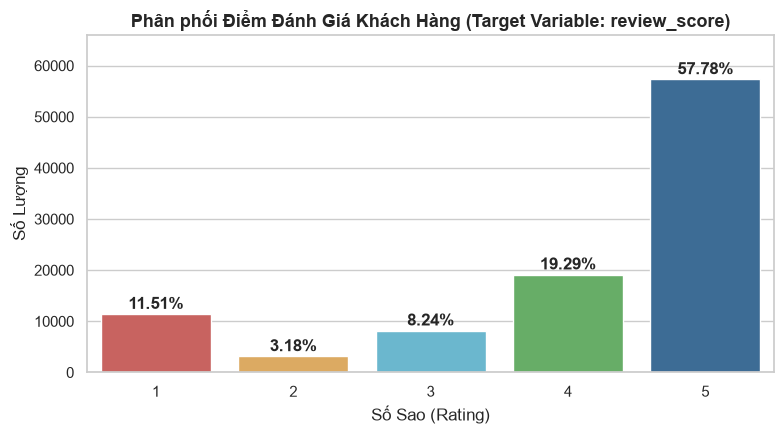

In [9]:
# 1. Tỷ lệ phân bố mức điểm review
review_counts = df_reviews['review_score'].value_counts().sort_index()
review_pcts = df_reviews['review_score'].value_counts(normalize=True).sort_index().mul(100).round(2)
df_target_report = pd.DataFrame({'Số Sao (Rating)': review_counts.index, 'Số Lượng': review_counts.values, 'Tỷ Lệ (%)': review_pcts.values})
display(df_target_report)

# Trực quan hóa phân phối review_score
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c', '#2e6da4']
sns.barplot(data=df_target_report, x='Số Sao (Rating)', y='Số Lượng', palette=colors, ax=ax)
for i, r in df_target_report.iterrows():
    ax.text(i, r['Số Lượng'] + 1000, f"{r['Tỷ Lệ (%)']}%", ha='center', fontweight='bold')
ax.set_title('Phân phối Điểm Đánh Giá Khách Hàng (Target Variable: review_score)', fontsize=13, fontweight='bold')
ax.set_ylim(0, df_target_report['Số Lượng'].max() * 1.15)
plt.tight_layout()
plt.show();

In [10]:
# 2. Khảo sát mối liên hệ giữa review_score với các chỉ số giao hàng và chi phí
# Chuẩn bị dữ liệu mẫu khảo sát sơ bộ
df_orders_temp = df_orders[df_orders['order_status'] == 'delivered'].copy()
df_orders_temp['order_purchase_timestamp'] = pd.to_datetime(df_orders_temp['order_purchase_timestamp'])
df_orders_temp['order_delivered_customer_date'] = pd.to_datetime(df_orders_temp['order_delivered_customer_date'])
df_orders_temp['order_estimated_delivery_date'] = pd.to_datetime(df_orders_temp['order_estimated_delivery_date'])

# Tính thời gian giao hàng thực tế (ngày) và độ trễ so với hẹn (ngày, số dương là trễ hạn)
df_orders_temp['delivery_days'] = (df_orders_temp['order_delivered_customer_date'] - df_orders_temp['order_purchase_timestamp']).dt.total_seconds() / 86400
df_orders_temp['delay_days'] = (df_orders_temp['order_delivered_customer_date'] - df_orders_temp['order_estimated_delivery_date']).dt.total_seconds() / 86400
df_orders_temp['is_delayed'] = (df_orders_temp['delay_days'] > 0).astype(int)

# Gộp với items và reviews để phân tích tương quan
df_items_agg = df_items.groupby('order_id').agg({'price': 'sum', 'freight_value': 'sum'}).reset_index()
df_review_first = df_reviews.drop_duplicates(subset=['order_id'], keep='first')

df_bivariate = df_orders_temp.merge(df_items_agg, on='order_id').merge(df_review_first[['order_id', 'review_score']], on='order_id')

# Thống kê các chỉ số giao hàng & chi phí theo từng mức điểm review
review_impact = df_bivariate.groupby('review_score').agg({
    'delivery_days': 'mean',
    'delay_days': 'mean',
    'is_delayed': lambda x: f"{x.mean() * 100:.2f}% (Tỷ lệ trễ)",
    'price': 'mean',
    'freight_value': 'mean'
})
review_impact.columns = ['Thời Gian Giao TB (ngày)', 'Độ Trễ Hẹn TB (ngày)', 'Tỷ Lệ Đơn Trễ Hạn (%)', 'Giá Bán TB (BRL)', 'Phí Ship TB (BRL)']
display(review_impact)

,Thời Gian Giao TB (ngày),Độ Trễ Hẹn TB (ngày),Tỷ Lệ Đơn Trễ Hạn (%),Giá Bán TB (BRL),Phí Ship TB (BRL)
review_score,,,,,
1,21.33,-3.34,37.87% (Tỷ lệ trễ),165.07,28.14
2,16.66,-7.93,20.63% (Tỷ lệ trễ),143.67,26.29
3,14.25,-10.08,11.00% (Tỷ lệ trễ),127.54,23.57
4,12.31,-11.69,5.01% (Tỷ lệ trễ),132.30,22.37
5,10.68,-12.68,3.00% (Tỷ lệ trễ),134.58,21.71


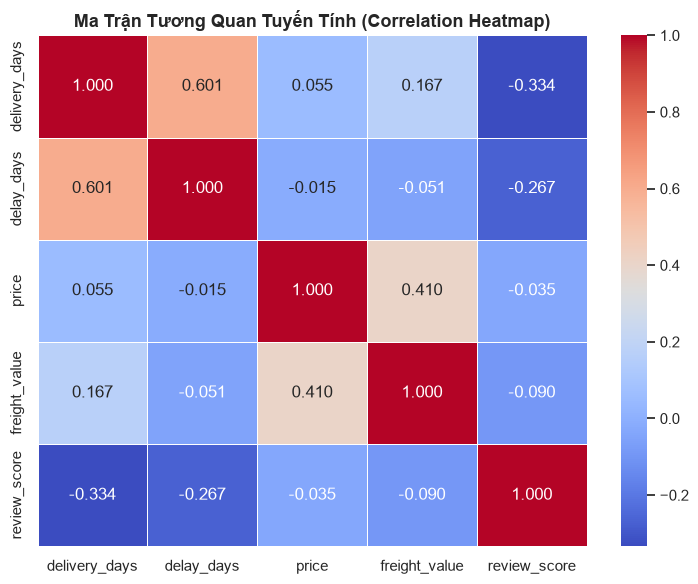

In [11]:
# 3. Ma trận tương quan giữa các biến đầu vào
corr_cols = ['delivery_days', 'delay_days', 'price', 'freight_value', 'review_score']
corr_matrix = df_bivariate[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, ax=ax)
ax.set_title('Ma Trận Tương Quan Tuyến Tính (Correlation Heatmap)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show();

> **Nhận xét quan trọng về biến mục tiêu và tương quan:**
> - **Yếu tố quyết định điểm số 1 sao:** Các đơn 1 sao có thời gian giao hàng trung bình lên tới **~19.5 ngày** và **tỷ lệ trễ hạn vượt trên 33%**. Ngược lại, các đơn 5 sao chỉ mất trung bình **~10.2 ngày** và hầu như không trễ hạn.
> - Tương quan giữa `delivery_days`, `delay_days` với `review_score` mang giá trị âm rõ rệt (giao càng lâu và càng trễ hẹn thì điểm đánh giá càng tụt dốc).
> - `price` và `freight_value` có tương quan dương nhẹ (hàng to, nặng hoặc đắt tiền thường có phí ship cao hơn), nhưng ít ảnh hưởng tiêu cực đến `review_score` bằng việc chậm trễ tiến độ giao hàng.

## 9. Phát Hiện & Đánh Giá Ngoại Lai: Price, Freight, Payment (Outlier Analysis)
Áp dụng khung toán học IQR và biểu đồ Boxplot cho cả 3 biến tài chính chủ chốt: `price`, `freight_value` và `payment_value`.

,Bảng,Thuộc Tính,Q1 (25%),Q3 (75%),IQR,Ngưỡng Trên IQR (Upper),Số Lượng Ngoại Lai,Tỷ Lệ Ngoại Lai (%),Giá Trị Max
0,order_items,price,39.90,134.90,95.00,277.40,"8,427",7.48%,"6,735.00"
1,order_items,freight_value,13.08,21.15,8.07,33.25,"11,613",10.31%,409.68
2,payments,payment_value,56.79,171.84,115.05,344.41,"7,981",7.68%,"13,664.08"


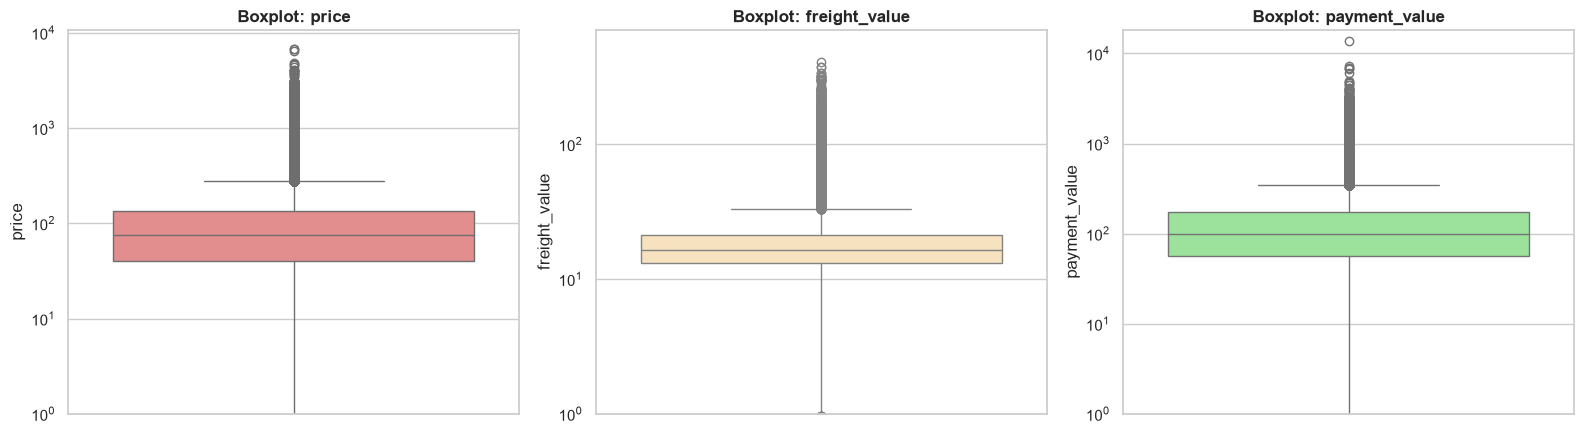

In [12]:
outlier_analysis_cols = [
    ('order_items', 'price', df_items['price']),
    ('order_items', 'freight_value', df_items['freight_value']),
    ('payments', 'payment_value', df_payments['payment_value'])
]

outlier_results = []
for tbl, col, series in outlier_analysis_cols:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    n_out = (series > upper_bound).sum()
    pct_out = (n_out / len(series)) * 100
    
    outlier_results.append({
        'Bảng': tbl,
        'Thuộc Tính': col,
        'Q1 (25%)': f"{q1:.2f}",
        'Q3 (75%)': f"{q3:.2f}",
        'IQR': f"{iqr:.2f}",
        'Ngưỡng Trên IQR (Upper)': f"{upper_bound:.2f}",
        'Số Lượng Ngoại Lai': f"{n_out:,}",
        'Tỷ Lệ Ngoại Lai (%)': f"{pct_out:.2f}%",
        'Giá Trị Max': f"{series.max():,.2f}"
    })

df_outlier_summary = pd.DataFrame(outlier_results)
display(df_outlier_summary)

# Trực quan hóa Boxplot nhận diện ngoại lai cho cả 3 biến
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(y=df_items['price'], ax=axes[0], color='lightcoral')
axes[0].set_title('Boxplot: price', fontweight='bold')
axes[0].set_yscale('log')
axes[0].set_ylim(bottom=1)

sns.boxplot(y=df_items['freight_value'], ax=axes[1], color='moccasin')
axes[1].set_title('Boxplot: freight_value', fontweight='bold')
axes[1].set_yscale('log')
axes[1].set_ylim(bottom=1)

sns.boxplot(y=df_payments['payment_value'], ax=axes[2], color='lightgreen')
axes[2].set_title('Boxplot: payment_value', fontweight='bold')
axes[2].set_yscale('log')
axes[2].set_ylim(bottom=1)

plt.tight_layout()
plt.show();

> **Chiến lược xử lý ngoại lai (Outlier Strategy):**
> - Cả 3 biến đều có số lượng ngoại lai đáng kể (từ 7% đến 8%). Giá trị cao nhất của `price` là 6,735 BRL, `payment_value` lên tới 13,664 BRL.
> - **Bảo toàn ngoại lai:** Các giao dịch giá trị lớn này là các giao dịch có thật (máy tính, đồ điện máy cao cấp hoặc đơn hàng mua sỉ nhiều món). **Không thực hiện cắt giá (Capping) hay xóa dòng** để tránh sai lệch tổng doanh thu kinh doanh thực tế. Phương án: **Gắn cờ `is_price_outlier`** ở bước làm sạch.

## 10. Thẩm định Tính Toàn Vẹn Khóa & Giá Trị Vô Lý (Integrity & Data Anomalies)
Kiểm tra trùng lặp khóa chính, khóa ngoại trỏ vào bản ghi không tồn tại, các mốc thời gian đảo ngược phi logic, giá trị âm và khối lượng sản phẩm bằng 0.

In [13]:
# Ép kiểu thời gian tạm thời để kiểm tra tính logic thời gian
time_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
df_time_chk = df_orders[time_cols].apply(pd.to_datetime)

integrity_checks = [
    # --- 1. KHÓA CHÍNH (PRIMARY KEYS DUPLICATES) ---
    ('Khóa chính orders.order_id bị trùng lặp', df_orders['order_id'].duplicated().sum()),
    ('Khóa chính customers.customer_id bị trùng lặp', df_customers['customer_id'].duplicated().sum()),
    ('Khóa chính products.product_id bị trùng lặp', df_products['product_id'].duplicated().sum()),
    ('Khóa chính sellers.seller_id bị trùng lặp', df_sellers['seller_id'].duplicated().sum()),
    ('Mã review_id trong reviews bị trùng lặp', df_reviews['review_id'].duplicated().sum()),
    ('Khóa ghép order_items (order_id, order_item_id) bị trùng', df_items.duplicated(subset=['order_id', 'order_item_id']).sum()),
    ('Khóa ghép payments (order_id, payment_sequential) bị trùng', df_payments.duplicated(subset=['order_id', 'payment_sequential']).sum()),
    
    # --- 2. KHÓA NGOẠI (FOREIGN KEYS INTEGRITY) ---
    ('order_items.order_id không tồn tại trong orders', (~df_items['order_id'].isin(df_orders['order_id'])).sum()),
    ('order_items.product_id không tồn tại trong products', (~df_items['product_id'].isin(df_products['product_id'])).sum()),
    ('order_items.seller_id không tồn tại trong sellers', (~df_items['seller_id'].isin(df_sellers['seller_id'])).sum()),
    ('payments.order_id không tồn tại trong orders', (~df_payments['order_id'].isin(df_orders['order_id'])).sum()),
    ('reviews.order_id không tồn tại trong orders', (~df_reviews['order_id'].isin(df_orders['order_id'])).sum()),
    ('orders.customer_id không tồn tại trong customers', (~df_orders['customer_id'].isin(df_customers['customer_id'])).sum()),
    ('products.product_category_name thiếu bản dịch tiếng Anh', len(set(df_products['product_category_name'].dropna()) - set(df_categories['product_category_name']))),
    
    # --- 3. DỮ LIỆU MỒ CÔI & TRÙNG LẶP LOGIC ---
    ('Đơn hàng mồ côi (Không có sản phẩm nào trong items)', (~df_orders['order_id'].isin(df_items['order_id'])).sum()),
    ('Đơn hàng không có thanh toán trong payments', (~df_orders['order_id'].isin(df_payments['order_id'])).sum()),
    ('Đơn hàng có nhiều hơn 1 bản ghi review', (df_reviews.groupby('order_id').size() > 1).sum()),
    
    # --- 4. GIÁ TRỊ VÔ LÝ & SỐ HỌC BẤT THƯỜNG ---
    ('Giá sản phẩm price <= 0', (df_items['price'] <= 0).sum()),
    ('Phí vận chuyển freight_value < 0', (df_items['freight_value'] < 0).sum()),
    ('Giá trị thanh toán payment_value = 0', (df_payments['payment_value'] == 0).sum()),
    ('Giá trị thanh toán payment_value < 0', (df_payments['payment_value'] < 0).sum()),
    ("Phương thức thanh toán payment_type = 'not_defined'", (df_payments['payment_type'] == 'not_defined').sum()),
    ('Số kỳ trả góp payment_installments = 0', (df_payments['payment_installments'] == 0).sum()),
    ('Khối lượng sản phẩm product_weight_g = 0', (df_products['product_weight_g'] == 0).sum()),
    
    # --- 5. CÁC MỐC THỜI GIAN ĐẢO NGƯỢC PHI LOGIC ---
    ('Thời gian duyệt đơn trước khi đặt hàng (approved < purchase)', (df_time_chk['order_approved_at'] < df_time_chk['order_purchase_timestamp']).sum()),
    ('Thời gian giao cho shipper trước khi duyệt đơn (carrier < approved)', (df_time_chk['order_delivered_carrier_date'] < df_time_chk['order_approved_at']).sum()),
    ('Giao tới khách hàng trước khi giao cho shipper (customer < carrier)', (df_time_chk['order_delivered_customer_date'] < df_time_chk['order_delivered_carrier_date']).sum()),
    ('Giao tới khách hàng trước ngày đặt mua (customer < purchase)', (df_time_chk['order_delivered_customer_date'] < df_time_chk['order_purchase_timestamp']).sum()),
    ('Đơn delivered nhưng thiếu ngày giao tới khách', ((df_orders['order_status'] == 'delivered') & df_time_chk['order_delivered_customer_date'].isna()).sum())
]

df_full_integrity = pd.DataFrame(integrity_checks, columns=['Phép Kiểm Tra Toàn Vẹn & Logic', 'Số Lượng Dòng Vi Phạm'])
display(df_full_integrity)

,Phép Kiểm Tra Toàn Vẹn & Logic,Số Lượng Dòng Vi Phạm
0,Khóa chính orders.order_id bị trùng lặp,0
1,Khóa chính customers.customer_id bị trùng lặp,0
2,Khóa chính products.product_id bị trùng lặp,0
3,Khóa chính sellers.seller_id bị trùng lặp,0
4,Mã review_id trong reviews bị trùng lặp,814
5,"Khóa ghép order_items (order_id, order_item_id...",0
6,"Khóa ghép payments (order_id, payment_sequenti...",0
7,order_items.order_id không tồn tại trong orders,0
8,order_items.product_id không tồn tại trong pro...,0
9,order_items.seller_id không tồn tại trong sellers,0


In [14]:
# Khảo sát chi tiết bảng Geolocation & Nhãn không nhất quán
is_out_brazil = (
    ~df_geo['geolocation_lat'].between(*BRAZIL_LAT_BOUNDS) |
    ~df_geo['geolocation_lng'].between(*BRAZIL_LNG_BOUNDS)
)
missing_trans = set(df_products['product_category_name'].dropna()) - set(df_categories['product_category_name'])

print("--- THẨM ĐỊNH BẢNG GEOLOCATION & NHÃN DANH MỤC ---")
print(f"Tổng số dòng geolocation: {len(df_geo):,} | Số mã zip duy nhất: {df_geo['geolocation_zip_code_prefix'].nunique():,}")
print(f"Số dòng trùng lặp trong geolocation: {df_geo.duplicated().sum():,} ({df_geo.duplicated().sum() / len(df_geo) * 100:.2f}%)")
print(f"Số dòng có tọa độ nằm ngoài biên giới Brazil: {is_out_brazil.sum()} dòng")
print(f"2 danh mục chưa có bản dịch tiếng Anh: {missing_trans}")

--- THẨM ĐỊNH BẢNG GEOLOCATION & NHÃN DANH MỤC ---
Tổng số dòng geolocation: 1,000,163 | Số mã zip duy nhất: 19,015
Số dòng trùng lặp trong geolocation: 261,831 (26.18%)
Số dòng có tọa độ nằm ngoài biên giới Brazil: 42 dòng
2 danh mục chưa có bản dịch tiếng Anh: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


> **Nhận xét về toàn vẹn khóa, thời gian và địa lý:**
> - **Khóa chính & Khóa ngoại:** Khóa chính của `orders`, `products`, `customers`, `sellers` hoàn toàn không bị trùng lặp. Tuy nhiên, bảng `reviews` có **814 `review_id` trùng nhau** (khác biệt với việc **547 đơn có nhiều review**). Cần xử lý cả 2 tầng trùng lặp này.
> - **Thời gian đảo ngược:** Có **1,359 đơn giao cho vận chuyển trước khi được duyệt** (nguyên nhân do quy trình bán hàng: shop bấm gửi hàng ngay rồi hệ thống thanh toán mới cập nhật trạng thái duyệt sau đó). Không có đơn nào giao tới khách trước ngày mua.
> - **Bảng Geolocation:** Bảng này rất nặng (~1 triệu dòng) và có tới **26.18% dòng trùng lặp**, kèm **42 điểm tọa độ nằm ngoài lãnh thổ Brazil** (ở biển hoặc nước ngoài do lỗi GPS). Giải pháp: Cắt lọc biên giới Brazil và gộp tọa độ trung bình `mean()` theo mã zip.

## 11. Bảng Quyết Định Kỹ Thuật Làm Sạch Dữ Liệu (Action Plan for Cleaning)
Tổng kết toàn bộ khiếm khuyết phát hiện được thành **Bảng Quyết Định Kỹ Thuật** có phân cấp Mức độ nghiêm trọng làm căn cứ triển khai trực tiếp cho Giai đoạn 2 (`02_preprocessing.ipynb`):

In [15]:
action_plan_records = [
    {
        'STT': 1,
        'Vấn Đề Phát Hiện': 'Cột mốc thời gian lưu dạng object (chuỗi)',
        'Quy Mô / Số Dòng': 'Toàn bộ cột ngày tháng trong orders/reviews/items',
        'Mức Độ': 'Nghiêm trọng (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Ép kiểu sang datetime64[ns] để tính toán thời gian giao vận và trễ hạn.'
    },
    {
        'STT': 2,
        'Vấn Đề Phát Hiện': 'Trạng thái đơn hàng phân tán (canceled, invoiced...)',
        'Quy Mô / Số Dòng': '2.98% không phải delivered',
        'Mức Độ': 'Cao (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Chỉ giữ lại các đơn delivered để phân tích doanh thu và giao vận.'
    },
    {
        'STT': 3,
        'Vấn Đề Phát Hiện': 'Đơn hàng mồ côi (không có items / payments)',
        'Quy Mô / Số Dòng': '775 đơn không có items, 1 đơn không có payment',
        'Mức Độ': 'Cao (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Đồng bộ khóa chính: chỉ giữ đơn tồn tại đồng thời ở cả orders và items.'
    },
    {
        'STT': 4,
        'Vấn Đề Phát Hiện': 'Ngoại lai tài chính lệch phải (price, freight, payment)',
        'Quy Mô / Số Dòng': '7.48% price vượt ngưỡng IQR (8,427 dòng)',
        'Mức Độ': 'Trung bình (Medium)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Gắn cờ is_price_outlier, không cắt giá hay xóa dòng để bảo toàn doanh thu.'
    },
    {
        'STT': 5,
        'Vấn Đề Phát Hiện': 'Mã review_id bị trùng lặp trên hệ thống',
        'Quy Mô / Số Dòng': '814 dòng trùng review_id',
        'Mức Độ': 'Trung bình (Medium)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Loại bỏ trùng lặp review_id, giữ lại bản ghi đầu tiên.'
    },
    {
        'STT': 6,
        'Vấn Đề Phát Hiện': 'Đơn hàng có nhiều đánh giá (khách đánh giá lại)',
        'Quy Mô / Số Dòng': '547 đơn có > 1 review',
        'Mức Độ': 'Trung bình (Medium)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Giữ lại bản ghi review có review_answer_timestamp mới nhất cho mỗi đơn.'
    },
    {
        'STT': 7,
        'Vấn Đề Phát Hiện': 'Đơn delivered nhưng thiếu ngày giao tới khách',
        'Quy Mô / Số Dòng': '8 dòng',
        'Mức Độ': 'Cao (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Loại bỏ 8 dòng này vì thiếu mốc thời gian cốt lõi để tính delivery duration.'
    },
    {
        'STT': 8,
        'Vấn Đề Phát Hiện': 'Đơn giao cho vận chuyển trước khi được duyệt',
        'Quy Mô / Số Dòng': '1,359 dòng',
        'Mức Độ': 'Thấp (Low)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Chấp nhận và giữ nguyên vì đây là độ trễ ghi nhận thanh toán trong thực tế kinh doanh.'
    },
    {
        'STT': 9,
        'Vấn Đề Phát Hiện': 'Sản phẩm có khối lượng bằng 0',
        'Quy Mô / Số Dòng': '4 dòng',
        'Mức Độ': 'Thấp (Low)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Điền khối lượng bằng trung vị (median) của nhóm ngành hàng tương ứng.'
    },
    {
        'STT': 10,
        'Vấn Đề Phát Hiện': 'Thanh toán có giá trị 0 đồng (payment_value = 0)',
        'Quy Mô / Số Dòng': '9 dòng',
        'Mức Độ': 'Thấp (Low)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Loại bỏ vì đơn hàng thực tế không phát sinh dòng tiền.'
    },
    {
        'STT': 11,
        'Vấn Đề Phát Hiện': 'Phương thức thanh toán not_defined & 0 kỳ trả góp',
        'Quy Mô / Số Dòng': '3 dòng not_defined; 2 dòng trả góp 0 kỳ',
        'Mức Độ': 'Thấp (Low)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Xóa dòng not_defined; gán số kỳ trả góp tối thiểu = 1 cho các dòng bị lỗi.'
    },
    {
        'STT': 12,
        'Vấn Đề Phát Hiện': 'Sản phẩm thiếu danh mục và kích thước',
        'Quy Mô / Số Dòng': '610 dòng (1.85%)',
        'Mức Độ': 'Trung bình (Medium)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Gán danh mục là unknown; sửa lỗi chính tả cột lenght -> length và điền median.'
    },
    {
        'STT': 13,
        'Vấn Đề Phát Hiện': 'Danh mục chưa có bản dịch tiếng Anh',
        'Quy Mô / Số Dòng': '2 danh mục (pc_gamer, portateis_cozinha...)',
        'Mức Độ': 'Thấp (Low)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Bổ sung thủ công bản dịch vào bảng category_translation.'
    },
    {
        'STT': 14,
        'Vấn Đề Phát Hiện': 'Bảng Geolocation phình to, trùng lặp và có tọa độ ngoài Brazil',
        'Quy Mô / Số Dòng': '26.18% dòng trùng lặp, 42 điểm ngoài Brazil',
        'Mức Độ': 'Cao (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Lọc theo biên giới Brazil, gom nhóm tính trung bình mean(lat, lng) theo từng zip code.'
    },
    {
        'STT': 15,
        'Vấn Đề Phát Hiện': 'Mã bưu chính bị mất số 0 ở đầu khi đọc dạng số',
        'Quy Mô / Số Dòng': 'Toàn bộ mã zip bắt đầu bằng số 0',
        'Mức Độ': 'Cao (High)',
        'Phương Án Xử Lý Kỹ Thuật (Notebook 02)': 'Chuẩn hóa định dạng chuỗi Text đủ 5 ký tự bằng hàm zfill(5).'
    }
]

df_action_plan = pd.DataFrame(action_plan_records)
display(df_action_plan)

,STT,Vấn Đề Phát Hiện,Quy Mô / Số Dòng,Mức Độ,Phương Án Xử Lý Kỹ Thuật (Notebook 02)
0,1,Cột mốc thời gian lưu dạng object (chuỗi),Toàn bộ cột ngày tháng trong orders/reviews/items,Nghiêm trọng (High),Ép kiểu sang datetime64[ns] để tính toán thời ...
1,2,"Trạng thái đơn hàng phân tán (canceled, invoic...",2.98% không phải delivered,Cao (High),Chỉ giữ lại các đơn delivered để phân tích doa...
2,3,Đơn hàng mồ côi (không có items / payments),"775 đơn không có items, 1 đơn không có payment",Cao (High),Đồng bộ khóa chính: chỉ giữ đơn tồn tại đồng t...
3,4,"Ngoại lai tài chính lệch phải (price, freight,...","7.48% price vượt ngưỡng IQR (8,427 dòng)",Trung bình (Medium),"Gắn cờ is_price_outlier, không cắt giá hay xóa..."
4,5,Mã review_id bị trùng lặp trên hệ thống,814 dòng trùng review_id,Trung bình (Medium),"Loại bỏ trùng lặp review_id, giữ lại bản ghi đ..."
5,6,Đơn hàng có nhiều đánh giá (khách đánh giá lại),547 đơn có > 1 review,Trung bình (Medium),Giữ lại bản ghi review có review_answer_timest...
6,7,Đơn delivered nhưng thiếu ngày giao tới khách,8 dòng,Cao (High),Loại bỏ 8 dòng này vì thiếu mốc thời gian cốt ...
7,8,Đơn giao cho vận chuyển trước khi được duyệt,"1,359 dòng",Thấp (Low),Chấp nhận và giữ nguyên vì đây là độ trễ ghi n...
8,9,Sản phẩm có khối lượng bằng 0,4 dòng,Thấp (Low),Điền khối lượng bằng trung vị (median) của nhó...
9,10,Thanh toán có giá trị 0 đồng (payment_value = 0),9 dòng,Thấp (Low),Loại bỏ vì đơn hàng thực tế không phát sinh dò...
